<a href="https://colab.research.google.com/github/eugenestumme-ai/genetic-algorithms-knapsack/blob/main/AIM350_A7_Stumme_1952.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
STUDENT_ID = 1952

In [ ]:
import numpy as np

# Extract digits from your 4-digit ID (pads leading zeros automatically)
sid_str = f"{STUDENT_ID:04d}"
d1, d2, d3, d4 = [int(ch) for ch in sid_str]

weights = np.array([d1 + 2, d2 + 3, d3 + 2, d4 + 3, 4])
values  = np.array([10 + d1, 12 + d2, 8 + d3, 15 + d4, 9])
C = int(np.floor(0.6 * weights.sum()))

print(f"SID4: {sid_str} -> digits: d1={d1}, d2={d2}, d3={d3}, d4={d4}")
print(f"Weights: {weights} (Sum = {weights.sum()})")
print(f"Values:  {values}")
print(f"Capacity C: {C}\n")

def eval_chrom(bits, pen=5):
    arr = np.array([int(b) for b in bits])
    W = int(arr @ weights)
    V = int(arr @ values)
    f = max(0, V - pen * max(0, W - C))
    feas = "Feasible" if W <= C else "Infeasible"
    return W, V, f, feas

# Task 1: Evaluate A-D
pop = {'A': '10110', 'B': '01101', 'C': '11010', 'D': '00111'}
print("--- TASK 1: INITIAL POPULATION ---")
fit_dict = {}
for name, bits in pop.items():
    W, V, f, feas = eval_chrom(bits)
    fit_dict[name] = f
    print(f"{name} ({bits}): W={W}, V={V}, f={f} ({feas})")

# Task 2: Roulette-Wheel Selection
print("\n--- TASK 2: SELECTION ---")
names = ['A', 'B', 'C', 'D']
f_vals = np.array([fit_dict[n] for n in names], dtype=float)
probs = f_vals / f_vals.sum()
cum_probs = np.cumsum(probs)
for n, p, q in zip(names, probs, cum_probs):
    print(f"{n}: prob = {p:.4f}, cum_prob = {q:.4f}")

r1, r2 = 0.28, 0.74
idx1 = int(np.where(cum_probs >= r1)[0][0])
idx2 = int(np.where(cum_probs >= r2)[0][0])
if idx1 == idx2:
    idx2 = (idx1 + 1) % 4
p1_name, p2_name = names[idx1], names[idx2]
p1_bits, p2_bits = pop[p1_name], pop[p2_name]
print(f"Selected: Parent 1 = {p1_name} ({p1_bits}), Parent 2 = {p2_name} ({p2_bits})")

# Task 3: Crossover, Mutation, Replacement
print("\n--- TASK 3: RECOMBINE, MUTATE, REPLACE ---")
off1_pre = p1_bits[:2] + p2_bits[2:]
off2 = p2_bits[:2] + p1_bits[2:]
flipped_bit4 = '1' if off1_pre[3] == '0' else '0'
off1_mut = off1_pre[:3] + flipped_bit4 + off1_pre[4:]

for label, bits in [("Offspring 1 (pre-mutation)", off1_pre),
                    ("Offspring 1 (mutated)     ", off1_mut),
                    ("Offspring 2               ", off2)]:
    W, V, f, feas = eval_chrom(bits)
    print(f"{label} [{bits}]: W={W}, V={V}, f={f} ({feas})")

# Steady-state replacement: drop 2 lowest fitness (tie-breaker: later in alphabet)
sorted_to_drop = sorted(names, key=lambda n: (fit_dict[n], -ord(n)))
dropped = sorted_to_drop[:2]
kept = [n for n in names if n not in dropped]

_, _, f_off1_mut, _ = eval_chrom(off1_mut)
_, _, f_off2, _ = eval_chrom(off2)

new_pop_fits = [fit_dict[n] for n in kept] + [f_off1_mut, f_off2]
print(f"Dropped from population: {dropped}, Kept: {kept}")
print(f"Old Pop -> Best: {max(f_vals):.2f}, Avg: {np.mean(f_vals):.2f}")
print(f"New Pop -> Best: {max(new_pop_fits):.2f}, Avg: {np.mean(new_pop_fits):.2f}")

# Task 4: True Optimal Load across all 32 chromosomes
print("\n--- TASK 4: TRUE OPTIMUM (EXHAUSTIVE SEARCH) ---")
best_val = -1
best_chroms = []
for i in range(32):
    bits = f"{i:05b}"
    W, V, f, feas = eval_chrom(bits)
    if W <= C:
        if V > best_val:
            best_val = V
            best_chroms = [(bits, W, V)]
        elif V == best_val:
            best_chroms.append((bits, W, V))
print(f"True Optimal Value = {best_val}")
for b, w, v in best_chroms:
    print(f"Optimal Chromosome: {b} (W={w}, V={v})")

SID4: 1952 -> digits: d1=1, d2=9, d3=5, d4=2
Weights: [ 3 12  7  5  4] (Sum = 31)
Values:  [11 21 13 17  9]
Capacity C: 18

--- TASK 1: INITIAL POPULATION ---
A (10110): W=15, V=41, f=41 (Feasible)
B (01101): W=23, V=43, f=18 (Infeasible)
C (11010): W=20, V=49, f=39 (Infeasible)
D (00111): W=16, V=39, f=39 (Feasible)

--- TASK 2: SELECTION ---
A: prob = 0.2993, cum_prob = 0.2993
B: prob = 0.1314, cum_prob = 0.4307
C: prob = 0.2847, cum_prob = 0.7153
D: prob = 0.2847, cum_prob = 1.0000
Selected: Parent 1 = A (10110), Parent 2 = D (00111)

--- TASK 3: RECOMBINE, MUTATE, REPLACE ---
Offspring 1 (pre-mutation) [10111]: W=19, V=50, f=45 (Infeasible)
Offspring 1 (mutated)      [10101]: W=14, V=33, f=33 (Feasible)
Offspring 2                [00110]: W=12, V=30, f=30 (Feasible)
Dropped from population: ['B', 'D'], Kept: ['A', 'C']
Old Pop -> Best: 41.00, Avg: 34.25
New Pop -> Best: 41.00, Avg: 35.75

--- TASK 4: TRUE OPTIMUM (EXHAUSTIVE SEARCH) ---
True Optimal Value = 41
Optimal Chromosome: 1

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def make_instance(student_id, n_items=25):
    """Builds YOUR personal knapsack instance from your student ID. Do not change."""
    rng = np.random.default_rng(int(student_id))
    weights = rng.integers(5, 31, n_items)
    values = rng.integers(10, 61, n_items)
    capacity = int(0.4 * weights.sum())
    return weights, values, capacity

def optimal_value(weights, values, capacity):
    """Exact optimum by dynamic programming (used only to measure how close the GA gets)."""
    best = np.zeros(capacity + 1, dtype=int)
    for w, v in zip(weights, values):
        for c in range(capacity, w - 1, -1):
            best[c] = max(best[c], best[c - w] + v)
    return int(best[capacity])

def fitness(pop, weights, values, capacity, penalty=10):
    """Penalty-function fitness (Lecture 7, 'Handling Constraints')."""
    W = pop @ weights
    V = pop @ values
    excess = np.maximum(0, W - capacity)
    return np.maximum(0, V - penalty * excess)

def tournament_select(pop, fit, k, rng):
    """Return ONE parent chosen by tournament selection of size k."""
    candidates = rng.choice(len(pop), size=k, replace=False)
    winner_idx = candidates[np.argmax(fit[candidates])]
    return pop[winner_idx].copy()

def single_point_crossover(p1, p2, pc, rng):
    if rng.random() < pc:
        cut = rng.integers(1, len(p1))
        return (np.concatenate([p1[:cut], p2[cut:]]),
                np.concatenate([p2[:cut], p1[cut:]]))
    return p1.copy(), p2.copy()

def bit_flip_mutation(child, pm, rng):
    """Flip each bit independently with probability pm; return the new child."""
    mask = rng.random(len(child)) < pm
    return np.where(mask, 1 - child, child)

def diversity(pop):
    """Average per-bit variance of the population (0 = all identical, 0.25 = maximum)."""
    return float(pop.var(axis=0).mean())

def run_ga(weights, values, capacity, pop_size=30, generations=100, pc=0.8,
           pm=0.04, k=3, n_elite=1, penalty=10, seed=0):
    rng = np.random.default_rng(seed)
    n = len(weights)
    pop = rng.integers(0, 2, (pop_size, n))
    hist = {"best": [], "avg": [], "div": []}
    for g in range(generations):
        fit = fitness(pop, weights, values, capacity, penalty)
        hist["best"].append(fit.max())
        hist["avg"].append(fit.mean())
        hist["div"].append(diversity(pop))

        elite = pop[np.argsort(fit)[::-1][:n_elite]]
        children = [e.copy() for e in elite]
        while len(children) < pop_size:
            p1 = tournament_select(pop, fit, k, rng)
            p2 = tournament_select(pop, fit, k, rng)
            c1, c2 = single_point_crossover(p1, p2, pc, rng)
            children.append(bit_flip_mutation(c1, pm, rng))
            if len(children) < pop_size:
                children.append(bit_flip_mutation(c2, pm, rng))
        pop = np.array(children)
    fit = fitness(pop, weights, values, capacity, penalty)
    best = pop[fit.argmax()]
    return best, {key: np.array(v) for key, v in hist.items()}

# Run Baseline Once for Task 1
weights_25, values_25, cap_25 = make_instance(STUDENT_ID)
opt_val = optimal_value(weights_25, values_25, cap_25)
best_sol, hist_base = run_ga(weights_25, values_25, cap_25, seed=STUDENT_ID * 100)
best_fit_single = fitness(best_sol.reshape(1, -1), weights_25, values_25, cap_25)[0]

print(f"Exact Optimal Value: {opt_val}")
print(f"Baseline Single-Run Best Fitness (seed={STUDENT_ID*100}): {best_fit_single}")

Exact Optimal Value: 597
Baseline Single-Run Best Fitness (seed=195200): 592


,Config,pm,k,Mean Final Best Fitness,% Gap to Optimum,Success Rate (/10),Mean Gen First Reached Best,Mean Final Diversity,Feasible Runs (/10)
0,Baseline,0.040,3,594.7,0.39,5/10,40.7,0.0639,10/10
1,Low mutation,0.001,3,509.3,14.69,0/10,16.4,0.0009,8/10
2,High mutation,0.250,3,552.3,7.49,0/10,41.4,0.2290,6/10
3,Low pressure,0.040,2,592.5,0.75,4/10,62.7,0.1068,10/10
4,High pressure,0.040,8,591.9,0.85,4/10,50.2,0.0382,10/10


Low mutation: Mean diversity first < 0.01 at generation: 12
High pressure: Mean diversity first < 0.01 at generation: Never (<0.01 not reached)
Baseline: Mean diversity first < 0.01 at generation: Never (<0.01 not reached)


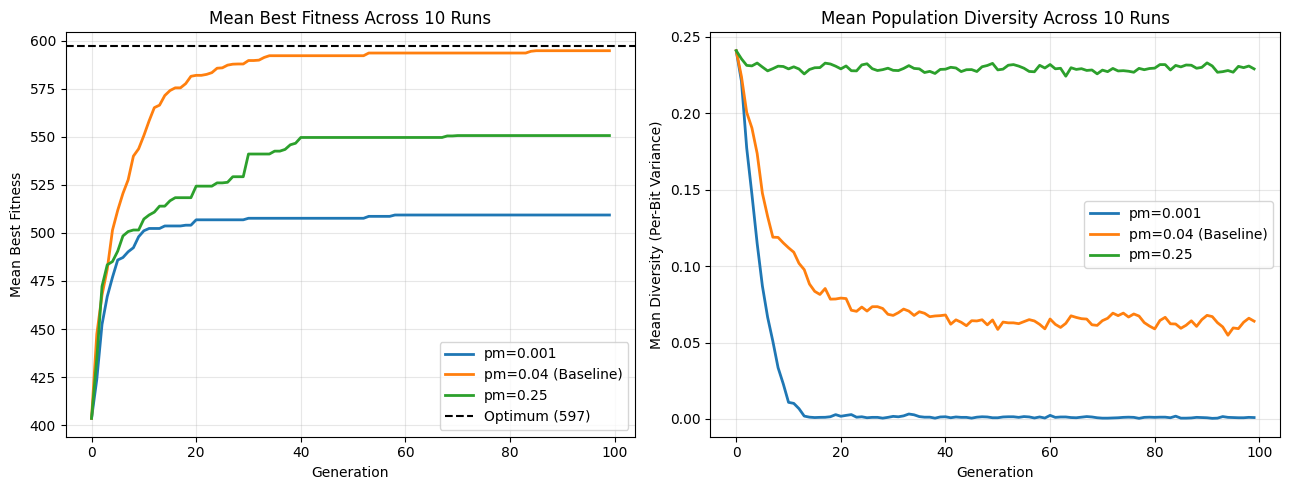

In [ ]:
configs = [
    ("Baseline",      0.04,  3),
    ("Low mutation",  0.001, 3),
    ("High mutation", 0.25,  3),
    ("Low pressure",  0.04,  2),
    ("High pressure", 0.04,  8),
]

table_rows = []
curves_best = {}
curves_div = {}

for name, pm, k in configs:
    final_bests = []
    first_gen_reached = []
    final_divs = []
    feasible_count = 0
    success_count = 0

    run_best_curves = []
    run_div_curves = []

    for r in range(10):
        seed = STUDENT_ID * 100 + r
        best_chrom, hist = run_ga(weights_25, values_25, cap_25,
                                  pop_size=30, generations=100, pc=0.8,
                                  pm=pm, k=k, n_elite=1, penalty=10, seed=seed)

        # Evaluate final best solution
        final_fit = float(fitness(best_chrom.reshape(1, -1), weights_25, values_25, cap_25, penalty=10)[0])
        final_W = int(best_chrom @ weights_25)

        best_curve = hist["best"]
        div_curve = hist["div"]

        run_best_curves.append(best_curve)
        run_div_curves.append(div_curve)

        # Final best fitness from history (with elitism=1, max of hist["best"] or final_fit)
        run_max_fit = max(float(best_curve.max()), final_fit)
        final_bests.append(run_max_fit)

        # First generation (0 to 99) where best fitness reached its final peak
        if best_curve.max() == run_max_fit:
            gen_reached = int(np.argmax(best_curve == run_max_fit))
        else:
            gen_reached = 100
        first_gen_reached.append(gen_reached)

        final_divs.append(float(div_curve[-1]))

        if final_W <= cap_25:
            feasible_count += 1
        if run_max_fit >= opt_val and final_W <= cap_25:
            success_count += 1

    mean_best = np.mean(final_bests)
    pct_gap = 100.0 * (opt_val - mean_best) / opt_val

    table_rows.append({
        "Config": name,
        "pm": pm,
        "k": k,
        "Mean Final Best Fitness": round(mean_best, 2),
        "% Gap to Optimum": round(pct_gap, 2),
        "Success Rate (/10)": f"{success_count}/10",
        "Mean Gen First Reached Best": round(np.mean(first_gen_reached), 1),
        "Mean Final Diversity": round(np.mean(final_divs), 4),
        "Feasible Runs (/10)": f"{feasible_count}/10"
    })

    curves_best[name] = np.mean(run_best_curves, axis=0)
    curves_div[name] = np.mean(run_div_curves, axis=0)

df_results = pd.DataFrame(table_rows)
display(df_results)

# Check exact generation where diversity drops < 0.01 for Task 3(i)
for name in ["Low mutation", "High pressure", "Baseline"]:
    below_001 = np.where(curves_div[name] < 0.01)[0]
    gen_001 = int(below_001[0]) if len(below_001) > 0 else "Never (<0.01 not reached)"
    print(f"{name}: Mean diversity first < 0.01 at generation: {gen_001}")

# Two-panel Plot for pm = 0.001, 0.04, 0.25
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
plot_configs = [("Low mutation", "pm=0.001"), ("Baseline", "pm=0.04 (Baseline)"), ("High mutation", "pm=0.25")]

for cfg_name, label in plot_configs:
    ax1.plot(curves_best[cfg_name], label=label, linewidth=2)
    ax2.plot(curves_div[cfg_name], label=label, linewidth=2)

ax1.axhline(opt_val, color='black', linestyle='--', label=f'Optimum ({opt_val})')
ax1.set_title("Mean Best Fitness Across 10 Runs")
ax1.set_xlabel("Generation")
ax1.set_ylabel("Mean Best Fitness")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.set_title("Mean Population Diversity Across 10 Runs")
ax2.set_xlabel("Generation")
ax2.set_ylabel("Mean Diversity (Per-Bit Variance)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Prediction (written before running)
Hypothesis: Removing elitism (n_elite = 0) from the Baseline configuration (pm = 0.04, k = 3) will degrade overall GA performance because the best individual found so far can be lost due to stochastic crossover and mutation without a guaranteed elite copy being passed to the next generation.

Numerical Prediction: The mean final best fitness will drop by at least 10 to 15 points compared to the Baseline, and the success rate across the 10 runs will drop from the baseline level down to 0/10 or 1/10.

In [ ]:
# TASK 4: Custom Experiment — Testing No Elitism (n_elite = 0)
final_bests_no_elite = []
first_gen_no_elite = []
final_divs_no_elite = []
feas_no_elite = 0
succ_no_elite = 0

for r in range(10):
    seed = STUDENT_ID * 100 + r
    best_chrom, hist = run_ga(weights_25, values_25, cap_25,
                              pop_size=30, generations=100, pc=0.8,
                              pm=0.04, k=3, n_elite=0, penalty=10, seed=seed)

    final_fit = float(fitness(best_chrom.reshape(1, -1), weights_25, values_25, cap_25, penalty=10)[0])
    final_W = int(best_chrom @ weights_25)

    # In a non-elitist GA, the final population's best fitness at gen 100 is final_fit
    final_bests_no_elite.append(final_fit)

    # First generation where the run reached its overall peak
    best_curve = hist["best"]
    gen_reached = int(np.argmax(best_curve == best_curve.max()))
    first_gen_no_elite.append(gen_reached)
    final_divs_no_elite.append(float(hist["div"][-1]))

    if final_W <= cap_25:
        feas_no_elite += 1
    if final_fit >= opt_val and final_W <= cap_25:
        succ_no_elite += 1

mean_best_ne = np.mean(final_bests_no_elite)
pct_gap_ne = 100.0 * (opt_val - mean_best_ne) / opt_val

df_exp4 = pd.DataFrame([{
    "Config": "No Elitism (n_elite=0)",
    "pm": 0.04,
    "k": 3,
    "Mean Final Best Fitness": round(mean_best_ne, 2),
    "% Gap to Optimum": round(pct_gap_ne, 2),
    "Success Rate (/10)": f"{succ_no_elite}/10",
    "Mean Gen First Reached Best": round(np.mean(first_gen_no_elite), 1),
    "Mean Final Diversity": round(np.mean(final_divs_no_elite), 4),
    "Feasible Runs (/10)": f"{feas_no_elite}/10"
}])
display(pd.concat([df_results.iloc[[0]], df_exp4], ignore_index=True))

,Config,pm,k,Mean Final Best Fitness,% Gap to Optimum,Success Rate (/10),Mean Gen First Reached Best,Mean Final Diversity,Feasible Runs (/10)
0,Baseline,0.04,3,594.7,0.39,5/10,40.7,0.0639,10/10
1,No Elitism (n_elite=0),0.04,3,579.2,2.98,0/10,40.2,0.0888,9/10
